In [1]:
import h5py
import json
import numpy as np
import matplotlib.pyplot as plt
import dedalus.public as d3
import diagnostics as diag
import logging
logger = logging.getLogger(__name__)

import matplotlib
matplotlib.rcParams['animation.embed_limit'] = 1000
matplotlib.use('TkAgg')
%matplotlib inline

In [2]:
# compute based on total temperature field

# mixing length
# diffusion from reynolds number / velocity field
# figure out C2 - ok

# derived diffusivity profiles
# tracer concentration profiles
# 2 rows: exponential profile -> different instances in time (solid line simulation + dashed line derived) + other profiles for diff initial concentrations
# report -> focus exponential, put others in appendix

In [3]:
run_id = 'rogers_0'
mode = 'test'
run_folder = diag.get_run_folder(run_id, mode)

with open(f'{run_folder}/info.json') as file:
    info = json.load(file)
params = info['params']
bg = info['background']
derived = info['derived']

f = diag.load_field_snapshots(run_folder, step=4)
p = diag.load_profile_snapshots(run_folder)

z_grid, x_grid, dT0dz = np.array(bg['z']), np.array(bg['x']), np.array(bg['dT0dz'])

In [4]:
field_arrays = diag.compute_field_arrays(f, bg['nu'])

In [5]:
frame = 15
t_mask_p = p['time'] > p['time'][-1] * 0.5
z_cross, depth = diag.compute_depth_from_KE(p, z_grid, bg['zb'], t_mask_p, 0.07)
print(params['L_cz'] / depth)

3.942732158997519


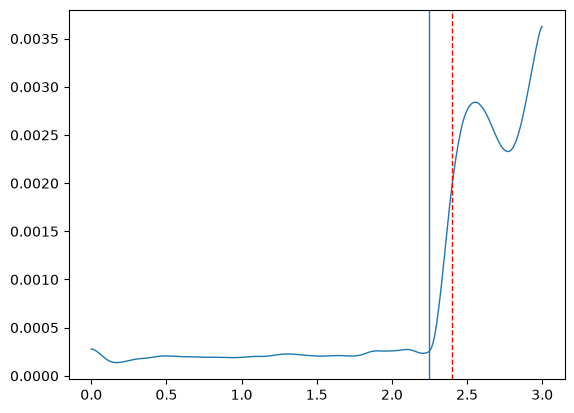

In [6]:
plt.plot(z_grid, p['KE_havg'][t_mask_p].mean(axis=0))
plt.axvline(bg['zb'], color='r', linestyle='--')
plt.axvline(z_cross)

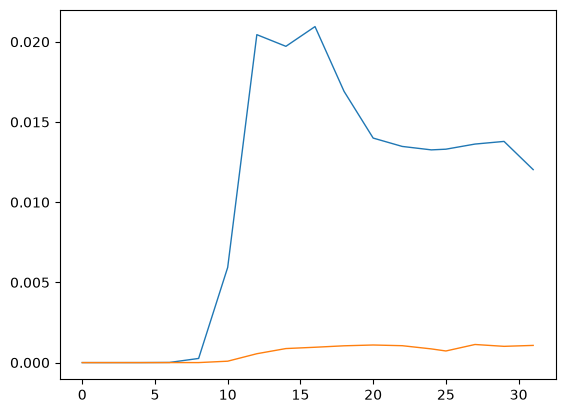

In [6]:
cz_mask = z_grid >= bg['zb']

cz = field_arrays['KE'][:,:,cz_mask].mean(axis=(1,2))
rz = field_arrays['KE'][:,:,~cz_mask].mean(axis=(1,2))
plt.plot(f['time'], cz)
plt.plot(f['time'], rz)
plt.show()

In [7]:
w_rms = diag.compute_w_rms(p)
t_mask = p['time'] > p['time'][-1] * 0.5
cz_mask = z_grid >= bg['zb']
w_rms[t_mask][:,cz_mask].mean()

np.float64(0.07685473931153859)

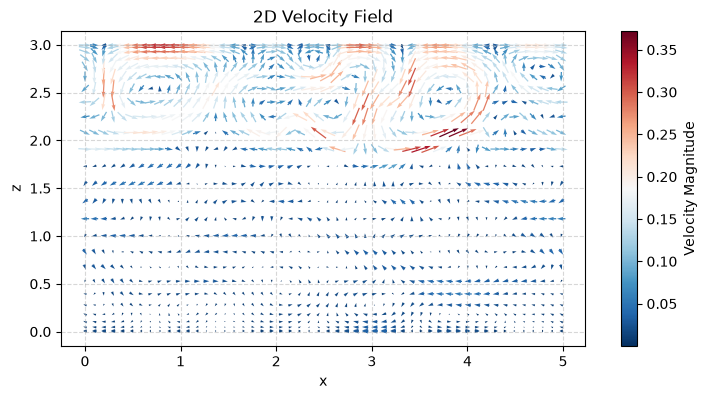

In [39]:
frame = 200
velocity = f['velocity']
'''
fig, ax = plt.subplots(1, 1, figsize=(8,3))
im = ax.pcolormesh(x.ravel(), z.ravel(), velocity[frame][1].T, shading='gouraud', cmap='RdBu_r')
fig.colorbar(im, ax=ax, label='velocity')
ax.set_xlabel('x')
ax.set_ylabel('z')
vmax_u = np.abs(velocity[:,1]).max()
vmax_theta = np.abs(theta).max()
im.set_clim(-vmax_u, vmax_u)
'''

x = x_grid.ravel()[::10]
z = z_grid.ravel()[::10]
u = velocity[frame][0].T[::10, ::10]
v = velocity[frame][1].T[::10, ::10]
mag = np.sqrt(u**2 + v**2)
u_scaled = u / np.sqrt(mag)
v_scaled = v / np.sqrt(mag)

plt.figure(figsize=(8,4))
quiver = plt.quiver(x, z, u_scaled, v_scaled, mag, cmap='RdBu_r', pivot='middle', angles='xy')

plt.colorbar(quiver, label='Velocity Magnitude')
plt.title('2D Velocity Field')
plt.xlabel('x')
plt.ylabel('z')
plt.grid(True, linestyle='--', alpha=0.5)

plt.gca().set_aspect('equal')

plt.tight_layout()

In [10]:
diag.w_interface(field_arrays['w'], z_grid, bg['zb'])

array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [-5.56830736e-05, -1.86337840e-04, -2.98046957e-04, ...,
        -7.86815216e-05, -3.33664329e-05, -5.12508619e-06],
       [-2.10804083e-04, -2.78016990e-04, -3.03408996e-04, ...,
        -1.47780752e-04, -1.36356099e-04, -1.55091011e-04],
       ...,
       [ 2.04879796e-02,  1.15587044e-02,  6.77976254e-03, ...,
         5.29978712e-02,  4.28260051e-02,  3.15750867e-02],
       [ 3.17272628e-02,  2.68768264e-02,  2.49676693e-02, ...,
         5.28729684e-02,  4.61685839e-02,  3.86500971e-02],
       [ 3.77787116e-02,  3.60072876e-02,  3.57628061e-02, ...,
         4.77105544e-02,  4.45466746e-02,  4.08706188e-02]],
      shape=(401, 256))

In [17]:
cz_mask = z_grid >= bg['zb'] + params['L_cz'] * 0.4

In [28]:
dT0dz_cz_ref = dT0dz[cz_mask].mean()    # -1

Nu, Nu_havg, F_cond = diag.compute_Nu(p, dT0dz, dT0dz_cz_ref, z_grid, bg['kappa'], cz_mask)
#Nu_havg = np.maximum(Nu_havg, 0)
'''
fig, ax = plt.subplots(figsize=(6, 3))
im = ax.pcolormesh(p['time'], z_grid, Nu_havg.T, shading='gouraud', cmap='RdBu_r');
fig.colorbar(im, ax=ax, label='Nu')
ax.set_xlabel('t')
ax.set_ylabel('z')
plt.close(fig)
fig.savefig(f'{run_id}_profiles.png', dpi=150)
'''
Nu_havg[1000]

array([-5.00010725, -4.9997545 , -4.99931664, -4.99865872, -4.99777799,
       -4.99667048, -4.99532829, -4.99373944, -4.99188384, -4.9897317 ,
       -4.98723722, -4.98433484, -4.9809302 , -4.97689463, -4.97205479,
       -4.9661883 , -4.9590161 , -4.95020426, -4.93936413, -4.92606462,
       -4.90984221, -4.89022249, -4.86673537, -4.83893788, -4.80642413,
       -4.76883867, -4.72587226, -4.67726047, -4.62276502, -4.56216308,
       -4.49522411, -4.42170312, -4.34132708, -4.25380488, -4.15883289,
       -4.05612725, -3.94544943, -3.82665772, -3.69974626, -3.56490696,
       -3.42257116, -3.27347084, -3.11867063, -2.9596163 , -2.79814475,
       -2.63650782, -2.47734834, -2.32368841, -2.17886125, -2.04645571,
       -1.93019698, -1.83384356, -1.76101554, -1.71504726, -1.69877201,
       -1.71434839, -1.76303218, -1.84502432, -1.95929577, -2.10353776,
       -2.27412442, -2.46623802, -2.67401336, -2.89084176, -3.10966061,
       -3.32336753, -3.52517081, -3.70902618, -3.86996594, -4.00

In [27]:
dtheta_havg_dz = np.gradient(p['theta_havg'], z_grid, axis=1)
F_cond = -bg['kappa'] * (dtheta_havg_dz + dT0dz)
Nu_havg = (p['F_conv_havg'] + F_cond) / (-bg['kappa'] * dT0dz)
Nu = Nu_havg[:,cz_mask].mean(axis=1)

Nu_havg[1000]

array([ 1.00002143,  0.99995088,  0.99986331,  0.99973172,  0.99955558,
        0.99933408,  0.99906564,  0.99874787,  0.99837675,  0.99794632,
        0.99744742,  0.99686695,  0.99618602,  0.99537891,  0.99441094,
        0.99323764,  0.9918032 ,  0.99004083,  0.98787281,  0.98521291,
        0.98196842,  0.97804448,  0.97334706,  0.96778756,  0.96128481,
        0.95376772,  0.94517443,  0.93545208,  0.92455299,  0.9124326 ,
        0.8990448 ,  0.88434061,  0.8682654 ,  0.85076096,  0.83176656,
        0.81122544,  0.78908987,  0.76533153,  0.73994924,  0.71298138,
        0.68451422,  0.65469415,  0.62373411,  0.59192325,  0.55962894,
        0.52730155,  0.49546966,  0.46473767,  0.43577224,  0.40929113,
        0.38603939,  0.3667687 ,  0.3522031 ,  0.34300945,  0.3397544 ,
        0.34286967,  0.35260643,  0.36900486,  0.39185915,  0.42070754,
        0.45482488,  0.49324759,  0.53480266,  0.57816834,  0.62193211,
        0.66467349,  0.70503415,  0.74180522,  0.77399317,  0.80